# Notebook 01: Khám phá Dữ liệu, Tiền xử lý & Phân chia Client (IID & Non-IID)

**Dự án:** Học liên kết (Federated Learning) cho phát hiện gian lận thẻ tín dụng  
**Người phụ trách:** Người 2 (Dữ liệu)  

---

### Mục tiêu chính:
1. **EDA & Làm sạch:** Kiểm tra giá trị thiếu, loại bỏ dòng trùng lặp (1.081 dòng) trên bộ dữ liệu `creditcard.csv`.
2. **Trực quan hóa:** Phân tích độ mất cân bằng lớp cực nặng (~0.167% gian lận), phân bố của `Amount` và `Time`.
3. **Phân chia Train / Test chống rò rỉ dữ liệu (No Data Leakage):** Tách 80/20 với `stratify=y, random_state=42`.
4. **Chuẩn hóa RobustScaler:** Chỉ fit trên tập Train, chỉ áp dụng cho 2 đặc trưng `Time` và `Amount` (giữ nguyên 28 thành phần PCA `V1`..`V28`).
5. **Phân chia 5 Client giả lập:**
   - **IID:** Chia đều stratified, mỗi client có tỷ lệ gian lận xấp xỉ nhau (~0.166%).
   - **Non-IID:** Sử dụng phân phối Dirichlet ($\alpha = 0.5$) với ràng buộc mỗi client sở hữu tối thiểu 30 mẫu gian lận.
6. **Bàn giao chuẩn hóa:** Lưu các tệp `.npz`, `.pkl` và cung cấp giao diện lập trình qua module `data_utils.py`.

In [1]:
import sys
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import RobustScaler

# Thiết lập đường dẫn import project root
project_root = Path("..").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import config
import data_utils

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
print(f"Cấu hình nạp thành công! Random Seed: {config.SEED}")

2026-11-01 20:31:00.841473: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-01 20:31:00.910363: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-01 20:31:00.910415: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-01 20:31:00.910522: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-01 20:31:00.925292: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-01 20:31:00.926076: I tensorflow/core/platform/cpu_feature_guard.cc:182] This Tens

2026-11-01 20:31:02.253321: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


Cấu hình nạp thành công! Random Seed: 42


## 1. Tải dữ liệu và Kiểm tra ban đầu (Data Ingestion)

In [2]:
raw_path = config.RAW_DATA_FILE
print(f"Đang đọc dữ liệu từ: {raw_path}")
df = pd.read_csv(raw_path)
print(f"Kích thước ban đầu: {df.shape[0]:,} dòng, {df.shape[1]} cột")
df.head()

Đang đọc dữ liệu từ: /mnt/e/baitap/Nam4/Cloud/Do_an/data/raw/creditcard.csv


Kích thước ban đầu: 284,807 dòng, 31 cột


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# Kiểm tra giá trị thiếu và trùng lặp
print(f"Số lượng giá trị thiếu (NaN): {df.isnull().sum().sum()}")
dup_count = df.duplicated().sum()
print(f"Số dòng trùng lặp phát hiện: {dup_count:,}")

if dup_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"-> Đã loại bỏ dòng trùng lặp. Kích thước dữ liệu sạch: {df.shape[0]:,} dòng")

Số lượng giá trị thiếu (NaN): 0


Số dòng trùng lặp phát hiện: 1,081


-> Đã loại bỏ dòng trùng lặp. Kích thước dữ liệu sạch: 283,726 dòng


## 2. Phân tích Khám phá Dữ liệu (EDA)
Khảo sát sự chênh lệch lớn giữa giao dịch hợp lệ (Class 0) và gian lận (Class 1).

Giao dịch hợp lệ (Class 0): 283,253 (99.833%)
Giao dịch gian lận (Class 1): 473 (0.167%)


/tmp/ipykernel_1247/2225467289.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=config.TARGET_COLUMN, data=df, ax=axes[0], palette=["#2ecc71", "#e74c3c"])


/tmp/ipykernel_1247/2225467289.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(["Hợp lệ (0)", "Gian lận (1)"])


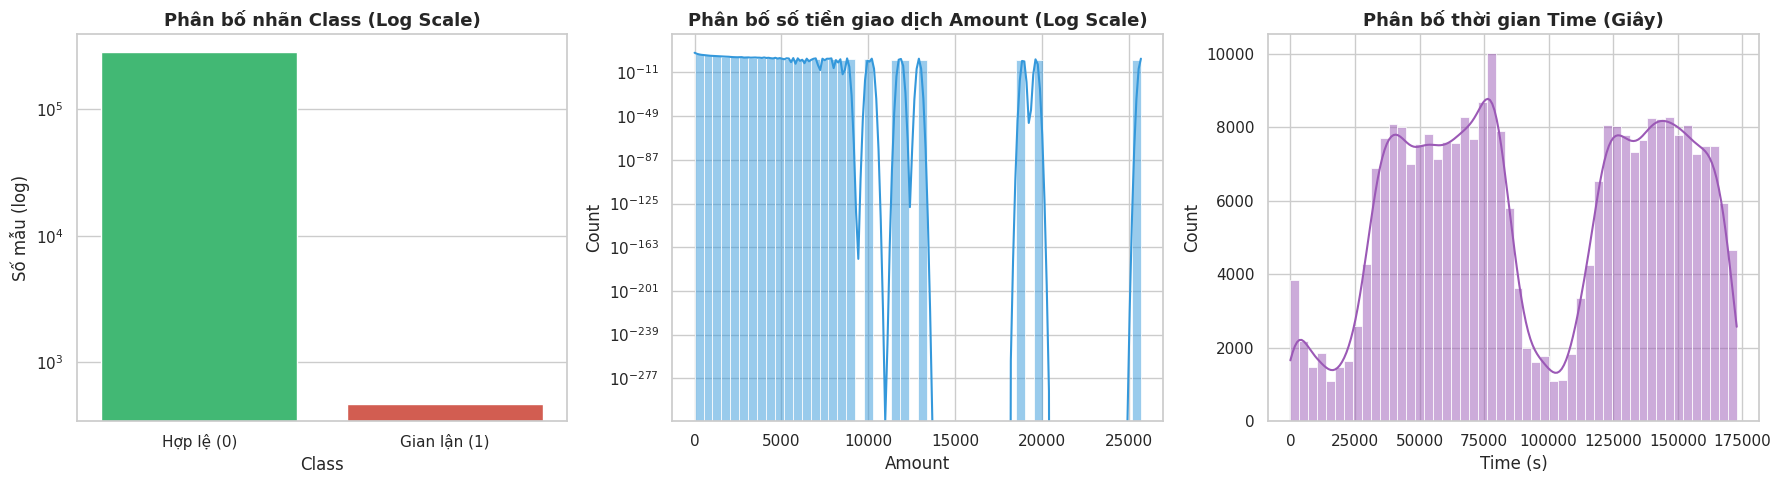

In [4]:
class_counts = df[config.TARGET_COLUMN].value_counts()
fraud_count = class_counts.get(1, 0)
legit_count = class_counts.get(0, 0)
fraud_pct = (fraud_count / len(df)) * 100

print(f"Giao dịch hợp lệ (Class 0): {legit_count:,} ({100 - fraud_pct:.3f}%)")
print(f"Giao dịch gian lận (Class 1): {fraud_count:,} ({fraud_pct:.3f}%)")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Class Distribution
sns.countplot(x=config.TARGET_COLUMN, data=df, ax=axes[0], palette=["#2ecc71", "#e74c3c"])
axes[0].set_yscale("log")
axes[0].set_title("Phân bố nhãn Class (Log Scale)", fontsize=13, fontweight="bold")
axes[0].set_xticklabels(["Hợp lệ (0)", "Gian lận (1)"])
axes[0].set_ylabel("Số mẫu (log)")

# 2. Amount Distribution
sns.histplot(df["Amount"], bins=50, ax=axes[1], color="#3498db", kde=True)
axes[1].set_yscale("log")
axes[1].set_title("Phân bố số tiền giao dịch Amount (Log Scale)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Amount")

# 3. Time Distribution
sns.histplot(df["Time"], bins=50, ax=axes[2], color="#9b59b6", kde=True)
axes[2].set_title("Phân bố thời gian Time (Giây)", fontsize=13, fontweight="bold")
axes[2].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()

## 3. Phân chia Train/Test & Chuẩn hóa RobustScaler (Chống Data Leakage)
- Tách `X` (30 cột: `Time, V1..V28, Amount`) và `y` (`Class`).
- Chia 80% Train, 20% Test bằng `stratify=y`.
- `RobustScaler` được fit độc quyền trên tập Train, sau đó transform cho cả Train và Test.

In [5]:
X = df[config.FEATURE_COLUMNS].values
y = df[config.TARGET_COLUMN].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=config.TEST_SIZE,
    random_state=config.SEED,
    stratify=y
)
print(f"Kích thước tập Train: {X_train.shape[0]:,} mẫu | Gian lận: {int(np.sum(y_train == 1)):,}")
print(f"Kích thước tập Test:  {X_test.shape[0]:,} mẫu | Gian lận: {int(np.sum(y_test == 1)):,}")

# Fit RobustScaler trên Time (0) và Amount (29)
scale_cols = [0, 29]
scaler = RobustScaler()
X_train[:, scale_cols] = scaler.fit_transform(X_train[:, scale_cols])
X_test[:, scale_cols] = scaler.transform(X_test[:, scale_cols])

# Lưu trữ ra data/processed/
config.PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
np.savez_compressed(config.TRAIN_DATA_FILE, X=X_train.astype(np.float32), y=y_train.astype(np.float32))
np.savez_compressed(config.TEST_DATA_FILE, X=X_test.astype(np.float32), y=y_test.astype(np.float32))
with open(config.SCALER_FILE, "wb") as f:
    pickle.dump(scaler, f)

print("Đã lưu train.npz, test.npz và scaler.pkl thành công!")

Kích thước tập Train: 226,980 mẫu | Gian lận: 378
Kích thước tập Test:  56,746 mẫu | Gian lận: 95


Đã lưu train.npz, test.npz và scaler.pkl thành công!


## 4. Phân chia 5 Client giả lập: IID vs Non-IID

In [6]:
# 4.1 Phân chia IID (StratifiedKFold)
skf = StratifiedKFold(n_splits=config.NUM_CLIENTS, shuffle=True, random_state=config.SEED)
clients_iid = {}
for i, (_, c_idx) in enumerate(skf.split(X_train, y_train)):
    clients_iid[f"X_{i}"] = X_train[c_idx].astype(np.float32)
    clients_iid[f"y_{i}"] = y_train[c_idx].astype(np.float32)

np.savez_compressed(config.CLIENTS_IID_FILE, **clients_iid)

# 4.2 Phân chia Non-IID (Dirichlet alpha=0.5 với min_fraud=30)
rng = np.random.default_rng(config.SEED)
fraud_idx = np.where(y_train == 1)[0]
legit_idx = np.where(y_train == 0)[0]
rng.shuffle(fraud_idx)
rng.shuffle(legit_idx)

n_fraud, n_legit = len(fraud_idx), len(legit_idx)
min_f = 30
rem_f = n_fraud - (min_f * config.NUM_CLIENTS)

f_props = rng.dirichlet([0.5] * config.NUM_CLIENTS)
f_counts = [min_f + int(np.round(p * rem_f)) for p in f_props]
f_counts[-1] += n_fraud - sum(f_counts)

l_props = rng.dirichlet([20.0] * config.NUM_CLIENTS)
l_counts = [int(np.round(p * n_legit)) for p in l_props]
l_counts[-1] += n_legit - sum(l_counts)

clients_noniid = {}
f_p, l_p = 0, 0
for i in range(config.NUM_CLIENTS):
    c_idx = np.concatenate([fraud_idx[f_p:f_p+f_counts[i]], legit_idx[l_p:l_p+l_counts[i]]])
    rng.shuffle(c_idx)
    clients_noniid[f"X_{i}"] = X_train[c_idx].astype(np.float32)
    clients_noniid[f"y_{i}"] = y_train[c_idx].astype(np.float32)
    f_p += f_counts[i]
    l_p += l_counts[i]

np.savez_compressed(config.CLIENTS_NONIID_FILE, **clients_noniid)
print("Đã lưu clients_iid.npz và clients_noniid.npz thành công!")

Đã lưu clients_iid.npz và clients_noniid.npz thành công!


## 5. Thống kê & Trực quan hóa So sánh Phân phối 5 Client

,Client,IID Tổng,IID Gian lận,IID Tỷ lệ (%),Non-IID Tổng,Non-IID Gian lận,Non-IID Tỷ lệ (%)
0,Client 1,"45,396",75,0.1652%,"38,510",149,0.3869%
1,Client 2,"45,396",75,0.1652%,"52,428",31,0.0591%
2,Client 3,"45,396",76,0.1674%,"68,097",46,0.0676%
3,Client 4,"45,396",76,0.1674%,"32,855",78,0.2374%
4,Client 5,"45,396",76,0.1674%,"35,090",74,0.2109%


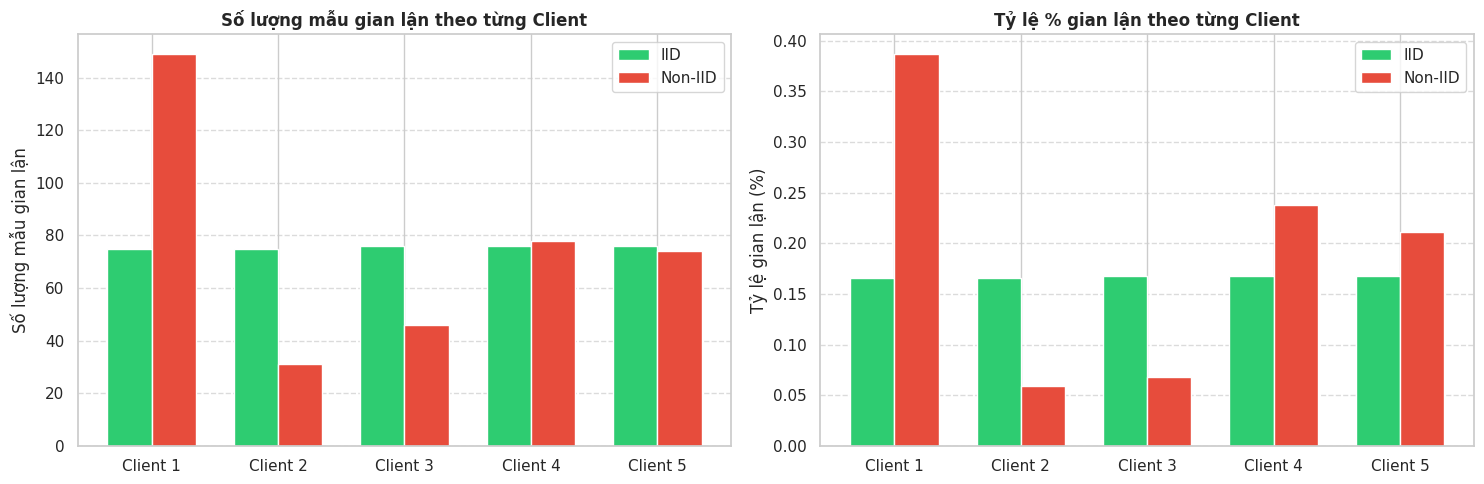

In [7]:
table_rows = []
for i in range(config.NUM_CLIENTS):
    y_i = clients_iid[f"y_{i}"]
    y_ni = clients_noniid[f"y_{i}"]
    table_rows.append({
        "Client": f"Client {i+1}",
        "IID Tổng": f"{len(y_i):,}",
        "IID Gian lận": int(np.sum(y_i == 1)),
        "IID Tỷ lệ (%)": f"{np.mean(y_i == 1) * 100:.4f}%",
        "Non-IID Tổng": f"{len(y_ni):,}",
        "Non-IID Gian lận": int(np.sum(y_ni == 1)),
        "Non-IID Tỷ lệ (%)": f"{np.mean(y_ni == 1) * 100:.4f}%",
    })

summary_df = pd.DataFrame(table_rows)
display(summary_df)

# Trực quan hóa so sánh
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
x = np.arange(config.NUM_CLIENTS)
w = 0.35
labels = [f"Client {i+1}" for i in range(config.NUM_CLIENTS)]

iid_fraud_vals = [int(np.sum(clients_iid[f"y_{i}"] == 1)) for i in range(config.NUM_CLIENTS)]
noniid_fraud_vals = [int(np.sum(clients_noniid[f"y_{i}"] == 1)) for i in range(config.NUM_CLIENTS)]

axes[0].bar(x - w/2, iid_fraud_vals, w, label="IID", color="#2ecc71")
axes[0].bar(x + w/2, noniid_fraud_vals, w, label="Non-IID", color="#e74c3c")
axes[0].set_title("Số lượng mẫu gian lận theo từng Client", fontsize=12, fontweight="bold")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylabel("Số lượng mẫu gian lận")
axes[0].legend()
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

iid_pct_vals = [np.mean(clients_iid[f"y_{i}"] == 1) * 100 for i in range(config.NUM_CLIENTS)]
noniid_pct_vals = [np.mean(clients_noniid[f"y_{i}"] == 1) * 100 for i in range(config.NUM_CLIENTS)]

axes[1].bar(x - w/2, iid_pct_vals, w, label="IID", color="#2ecc71")
axes[1].bar(x + w/2, noniid_pct_vals, w, label="Non-IID", color="#e74c3c")
axes[1].set_title("Tỷ lệ % gian lận theo từng Client", fontsize=12, fontweight="bold")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels)
axes[1].set_ylabel("Tỷ lệ gian lận (%)")
axes[1].legend()
axes[1].grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

## 6. Kiểm thử Tích hợp với Module `data_utils.py`
Kiểm tra tính sẵn sàng của các hàm dùng chung để Người 3 (Huấn luyện Federated) và Người 4 (Đánh giá) gọi trực tiếp.

In [8]:
# 1. Nạp tập dữ liệu gốc
X_tr, y_tr, X_te, y_te = data_utils.load_data()
print(f"X_train shape: {X_tr.shape} (dtype: {X_tr.dtype})")
print(f"y_train shape: {y_tr.shape} (dtype: {y_tr.dtype})")

# 2. Tạo datasets cho 5 clients theo chuẩn tf.data.Dataset của TFF
client_ds_list = data_utils.make_client_datasets("iid")
print(f"Số lượng client datasets: {len(client_ds_list)}")
print(f"Cấu trúc phần tử (Element Spec) chuẩn TFF: {client_ds_list[0].element_spec}")

# Lấy 1 batch kiểm tra
for b_x, b_y in client_ds_list[0].take(1):
    print(f"Batch X shape: {b_x.shape} | Batch y shape: {b_y.shape}")

# 3. Tính class weight cân bằng cho loss
cw = data_utils.get_class_weights(y_tr)
print(f"Trọng số class weight: {cw}")

X_train shape: (226980, 30) (dtype: float32)
y_train shape: (226980,) (dtype: float32)


Số lượng client datasets: 5
Cấu trúc phần tử (Element Spec) chuẩn TFF: (TensorSpec(shape=(None, 30), dtype=tf.float32, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None))
Batch X shape: (32, 30) | Batch y shape: (32, 1)
Trọng số class weight: {0: 0.5008340614822464, 1: 300.23809523809524}


2026-11-01 20:31:19.356290: I tensorflow/compiler/xla/stream_executor/cuda/cuda_gpu_executor.cc:880] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-11-01 20:31:19.357004: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2211] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...
